# UTAUT Data Example Workflow

**Author:** Cornel Gübeli
**Date:** 2026-09-24

## Objective
This notebook is playing around with an example dataset with UTAUT-Data

## Resources
Dataset source: https://data.mendeley.com/public-files/datasets/kcf54cgk78/files/01624585-4926-4b05-a3ab-8628b67ba57d/file_downloaded

Article: https://portal.findresearcher.sdu.dk/en/publications/elevating-theoretical-insight-and-predictive-accuracy-in-business/





In [3]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sklearn

In [ ]:
# import dataset

df = pd.read_csv(
    r"C:\Users\guebeli.SPW\Documents\Data_PhD_Guebeli\1_Example_Datasets\Richter (2023).csv",
    sep=";",
)

df.head()

,BI,EE,FC,PE,SN,USE
count,7.220000e+02,7.220000e+02,7.220000e+02,7.220000e+02,7.220000e+02,7.220000e+02
mean,1.940707e-14,-7.895439e-14,2.353058e-14,1.080527e-13,-6.234471e-14,4.172716e-15
std,1.000693e+00,1.000693e+00,1.000693e+00,1.000693e+00,1.000693e+00,1.000693e+00
min,-4.418467e+00,-4.205561e+00,-3.635021e+00,-5.944120e+00,-2.973287e+00,-2.826240e+00
25%,-6.089152e-01,-5.357565e-01,-5.605021e-01,-3.843523e-01,-4.942256e-01,-6.060132e-01
50%,1.005291e-01,1.764952e-01,1.401768e-01,4.411591e-01,1.937699e-01,1.374063e-01
75%,7.522808e-01,8.373897e-01,7.404925e-01,7.260057e-01,8.703160e-01,7.301160e-01
max,1.130623e+00,1.106786e+00,1.332990e+00,7.260057e-01,1.097800e+00,1.920882e+00


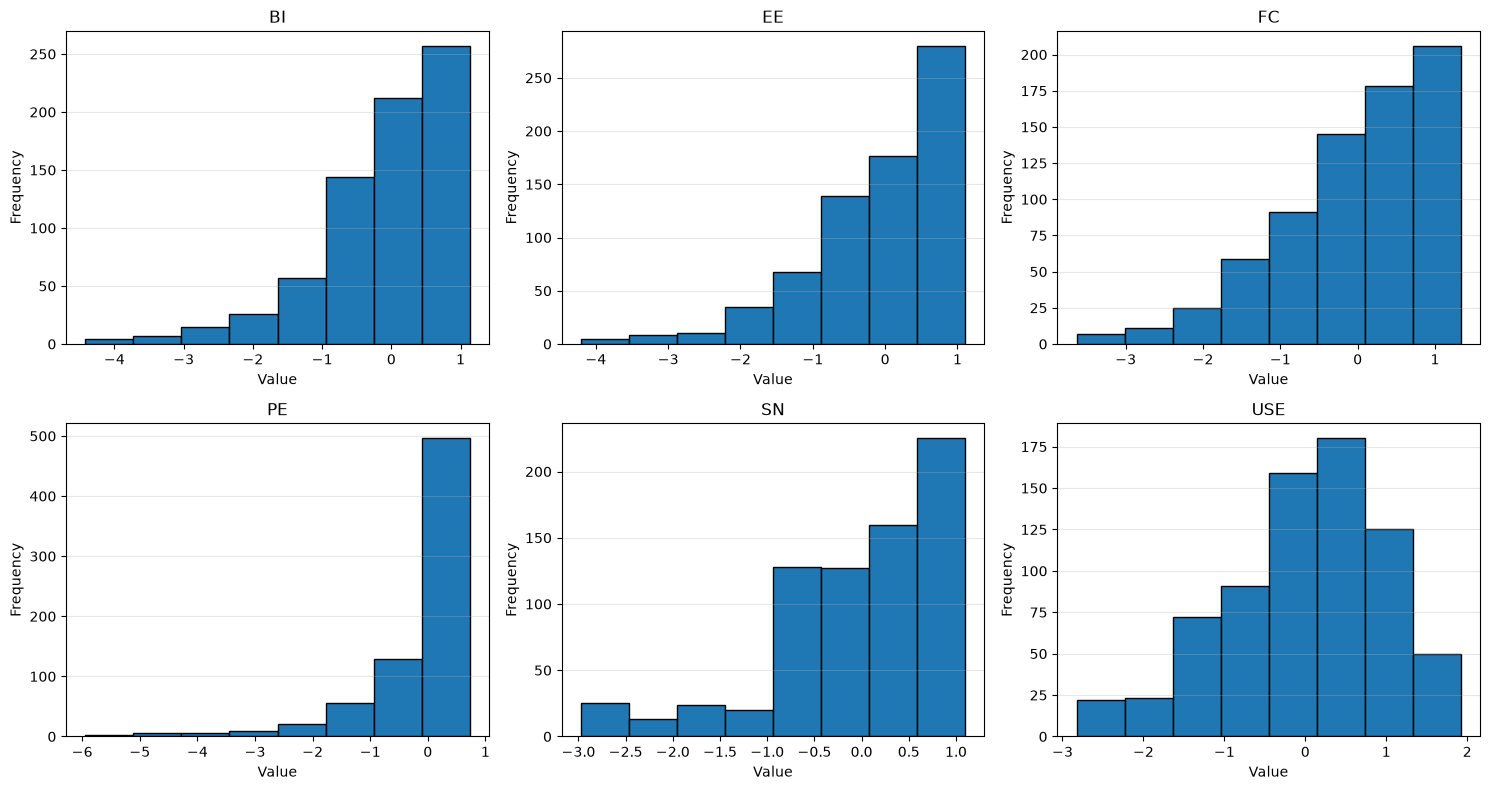

In [10]:
# Data exploration

# Histograms for all numerical features
numeric_features = df.select_dtypes(include="number").columns

n_cols = 3
n_rows = int(np.ceil(len(numeric_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, numeric_features):
    ax.hist(df[feature].dropna(), bins=8, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

# Hide unused subplots
for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()



In [9]:
# data analysis

# ...existing code...

from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score
import numpy as np

# Basic safety check
required_cols = ["EE", "PE", "SN", "BI", "FC", "USE"]
missing = [c for c in required_cols if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns in df: {missing}. Please rename the variables to match the UTAUT names.")

# Remove rows with missing values in the variables used
df_model = df[required_cols].dropna().copy()

# ---------------------------
# Step 1: EE, PE, SN -> BI
# ---------------------------
X1 = df_model[["EE", "PE", "SN"]].astype(float)
y1 = df_model["BI"].astype(float)

pls1 = PLSRegression(n_components=1)
pls1.fit(X1, y1)

y1_pred = pls1.predict(X1).ravel()
r2_stage1 = r2_score(y1, y1_pred)

# latent predictor score for the path coefficient
x1_score = pls1.x_scores_[:, 0]
path_BI = np.corrcoef(x1_score, y1)[0, 1]

print("Stage 1: EE, PE, SN -> BI")
print(f"R² = {r2_stage1:.4f}")
print(f"Structural path coefficient (corr. latent score vs BI) = {path_BI:.4f}")

# ---------------------------
# Step 2: BI, FC -> USE
# ---------------------------
X2 = df_model[["BI", "FC"]].astype(float)
y2 = df_model["USE"].astype(float)

pls2 = PLSRegression(n_components=1)
pls2.fit(X2, y2)

y2_pred = pls2.predict(X2).ravel()
r2_stage2 = r2_score(y2, y2_pred)

x2_score = pls2.x_scores_[:, 0]
path_USE = np.corrcoef(x2_score, y2)[0, 1]

print("\nStage 2: BI, FC -> USE")
print(f"R² = {r2_stage2:.4f}")
print(f"Structural path coefficient (corr. latent score vs USE) = {path_USE:.4f}")


Stage 1: EE, PE, SN -> BI
R² = 0.3628
Structural path coefficient (corr. latent score vs BI) = 0.6023

Stage 2: BI, FC -> USE
R² = 0.2333
Structural path coefficient (corr. latent score vs USE) = 0.4830
